# 02 — Linear Regression with MLForge

Predict a numerical measure of diabetes progression from baseline
measurements using our NumPy least-squares implementation. We evaluate
predictions on a held-out test set rather than on training data.

Dataset: [scikit-learn Diabetes](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html).
The target is a progression measure one year after baseline; features
include age, coded sex, BMI, blood pressure, and serum measurements.
No external data download is required.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from mlforge import LinearRegression

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
assert LinearRegression.__module__ == "mlforge.linear_regression"

## 1. Load raw features and split the data

scaled=False avoids the loader's complete-dataset normalization.
We make a reproducible 80/20 split before computing preprocessing
statistics. All ten features are retained; the test set is not used
for feature selection or model fitting.

In [2]:
dataset = load_diabetes(as_frame=True, scaled=False)
X, y = dataset.data, dataset.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
assert set(X_train.index).isdisjoint(X_test.index)
display(pd.Series({
    "Total observations": len(X),
    "Features": X.shape[1],
    "Training observations": len(X_train),
    "Test observations": len(X_test),
}, name="Dataset and split").to_frame())

,Dataset and split
Total observations,442
Features,10
Training observations,353
Test observations,89


## 2. Explore the training data

Check missing values and summarize the training target. A BMI scatter
plot gives a simple view of one feature's relationship to progression;
the model itself will use all ten features.

Missing training values: 0


,Training target
count,353.00
mean,153.74
std,78.06
min,25.00
25%,86.00
50%,142.00
75%,214.00
max,346.00


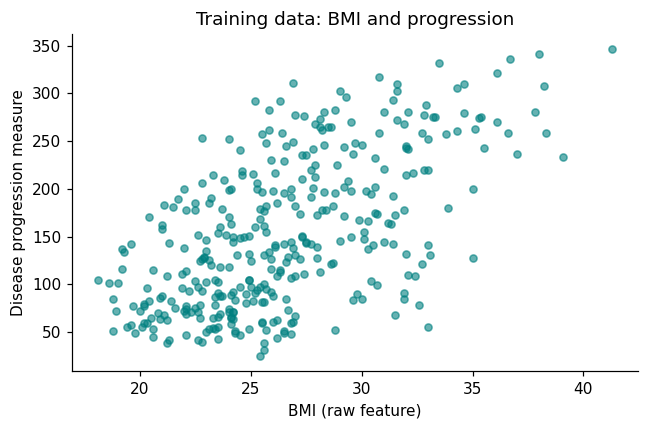

In [3]:
assert X_train.isna().sum().sum() == 0
assert y_train.isna().sum() == 0
print("Missing training values:", int(X_train.isna().sum().sum()))
display(y_train.describe().round(2).to_frame("Training target"))

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(X_train["bmi"], y_train, alpha=0.6, s=22, color="teal")
ax.set(title="Training data: BMI and progression",
       xlabel="BMI (raw feature)", ylabel="Disease progression measure")
fig.tight_layout()
plt.show()

## 3. Standardize using training data only

Least squares with an intercept does not require standardization,
but scaling makes differently sized feature columns easier to work
with and improves numerical conditioning. Fit the scaler only on
training rows and apply the same transformation to test rows.
Keep the target in its original units.

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
assert scaler.n_samples_seen_ == len(X_train)
np.testing.assert_allclose(scaler.mean_, X_train.mean().to_numpy())
np.testing.assert_allclose(X_train_scaled.mean(axis=0), 0.0, atol=1e-12)

## 4. Train the custom model and predict

MLForge fits an intercept and coefficients by minimizing squared errors
with NumPy's least-squares solver. Scikit-learn is used for utilities,
not for the regression model.

In [5]:
model = LinearRegression(fit_intercept=True)
model.fit(X_train_scaled, y_train)
predictions = model.predict(X_test_scaled)
assert predictions.shape == y_test.shape
assert np.all(np.isfinite(predictions))
display(pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": predictions,
}).head().round(2))

,Actual,Predicted
0,219.0,139.55
1,70.0,179.52
2,202.0,134.04
3,230.0,291.42
4,111.0,123.79


## 5. Evaluate held-out predictions

R² compares squared prediction error with variation around the test
target mean. Higher is better, and negative scores are possible.
MSE is the mean squared error; RMSE is its square root, in the target's
original units. Lower MSE and RMSE are better.

In [6]:
r_squared = model.score(X_test_scaled, y_test)
mse = mean_squared_error(y_test, predictions)
rmse = float(np.sqrt(mse))
np.testing.assert_allclose(r_squared, r2_score(y_test, predictions))
np.testing.assert_allclose(rmse ** 2, mse)
assert np.all(np.isfinite([r_squared, mse, rmse]))
assert r_squared <= 1.0 and mse >= 0.0 and rmse >= 0.0
display(pd.Series({
    "R²": r_squared,
    "MSE": mse,
    "RMSE": rmse,
}, name="Test performance").round(4).to_frame())

,Test performance
R²,0.4526
MSE,2900.1936
RMSE,53.8534


## 6. Compare actual and predicted values

Points on the dashed line would be perfect predictions. Distance from
the line shows prediction error. This is a test-set plot, so it shows
performance on observations the model did not use during fitting.

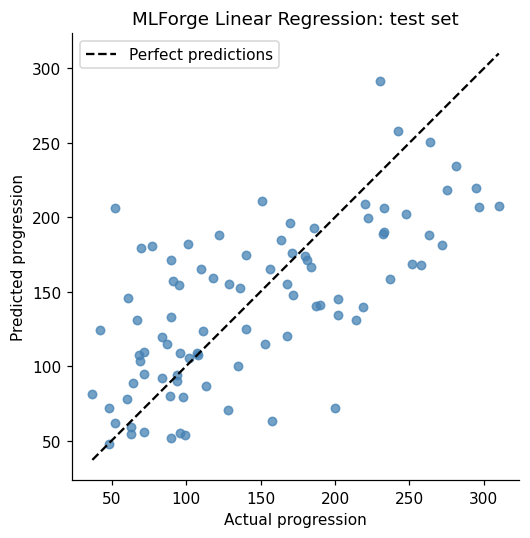

In [7]:
limits = [min(y_test.min(), predictions.min()),
          max(y_test.max(), predictions.max())]
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, predictions, alpha=0.75, s=30, color="steelblue")
ax.plot(limits, limits, "k--", label="Perfect predictions")
ax.set(title="MLForge Linear Regression: test set",
       xlabel="Actual progression", ylabel="Predicted progression")
ax.set_aspect("equal", adjustable="box")
ax.legend()
fig.tight_layout()
plt.show()

## 7. Analyze prediction errors

Mean absolute error (MAE) is the average absolute difference
between actual and predicted values. It uses the target's original
units, and lower values indicate smaller errors.

We also examine residuals, defined as:

residual = actual value - predicted value

- A positive residual means the model underestimates the actual value.
- A negative residual means the model overestimates the actual value.
- The horizontal zero line represents a prediction with no error.

Plotting residuals against predictions helps reveal systematic
patterns or changes in error spread that a single metric can hide.
This analysis describes the existing test predictions; it is not
used to tune the model.

Test MAE: 42.7941


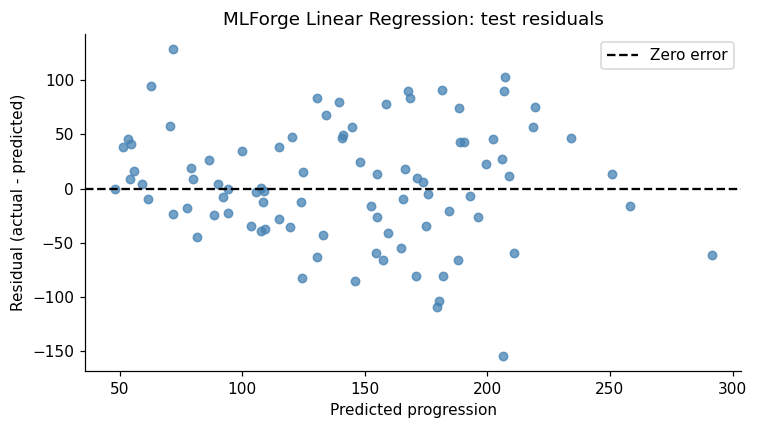

In [8]:
from sklearn.metrics import mean_absolute_error

residuals = y_test.to_numpy() - predictions
mae = mean_absolute_error(y_test, predictions)

np.testing.assert_allclose(mae, np.mean(np.abs(residuals)))
print(f"Test MAE: {mae:.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(
    predictions, residuals,
    alpha=0.75, s=30, color="steelblue"
)
ax.axhline(0, color="black", linestyle="--", label="Zero error")
ax.set(
    title="MLForge Linear Regression: test residuals",
    xlabel="Predicted progression",
    ylabel="Residual (actual - predicted)",
)
ax.legend()
fig.tight_layout()
plt.show()

### Interpretation

The test MAE is **42.7941**, meaning that predictions differ from
actual progression values by about **42.79 target units on average
in absolute terms**.

Residuals appear on both sides of zero, so the model makes both
underestimates and overestimates. Several errors exceed 100 target
units in magnitude, showing that an average metric can hide large
individual errors.

The MAE is lower than the RMSE of **53.8534**, consistent with RMSE
giving greater weight to large errors. This plot alone does not
establish that the residuals are normally distributed or have
constant variance.

These findings describe one fixed test split and do not establish
performance on other populations.

## 8. Compare with a training-mean baseline

Does the regression model outperform a predictor that ignores
all input features?

Our baseline predicts the training target mean for every test
observation. The mean is calculated from training labels only;
test labels are used only to evaluate predictions.

We compare the baseline and MLForge using MAE and RMSE on the
same test observations. Lower values indicate smaller errors.

The mean is the constant prediction that minimizes training
squared error. It is not necessarily the constant that minimizes
absolute error; that would be the training median.

In [9]:
training_mean = float(y_train.mean())
baseline_predictions = np.full(len(y_test), training_mean)

comparison = pd.DataFrame({
    "Model": ["Training-mean baseline", "MLForge Linear Regression"],
    "MAE": [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(y_test, predictions),
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, baseline_predictions)),
        np.sqrt(mean_squared_error(y_test, predictions)),
    ],
}).set_index("Model")

print(f"Training target mean: {training_mean:.4f}")
display(comparison.round(4))

Training target mean: 153.7365


,MAE,RMSE
Model,,
Training-mean baseline,64.0065,73.2225
MLForge Linear Regression,42.7941,53.8534


### Baseline comparison results

The training-mean baseline predicts **153.7365** for every test
observation. Its test MAE is **64.0065** and RMSE is **73.2225**.

MLForge achieves a lower MAE of **42.7941** and RMSE of **53.8534**.
On this test split, using the input features therefore improves
prediction over a constant training-mean prediction.

This comparison provides context for the model's scores, but does
not establish performance across other splits or populations.

## Conclusion

On the 89 held-out observations, MLForge achieves R² = **0.4526**, MSE = **2900.1936**, and RMSE = **53.8534**. The model captures some variation, but the scatter around the diagonal shows substantial prediction error. RMSE is measured in the target's original units.

This linear model and one fixed split provide a simple baseline, not a guarantee of performance on every sample. The scaler and model were fitted only on training rows.